# Búsqueda de punch-out: barrido en corriente + barrido en potencia

1. **Barrido en corriente** de la bobina a potencia fija: cómo responde el resonador al flujo.
   - curva suave y simétrica en I → efecto del campo en la inductancia cinética (Al granular)
   - escalones sin período + caída de Qi → vórtices
   - algo periódico en I o cruces evitados → qubit acoplado
2. **Barrido en potencia** en la corriente donde se ve el acoplamiento (y opcionalmente en una de referencia):
   si hay punch-out, a potencia alta el resonador salta a la frecuencia sin qubit, que no depende de la corriente.

Funciones en `barrido_flujo.py` (fuente, barrido en corriente, ajustes) y `vna_single.py` (VNA, barrido en potencia).

In [ ]:
# --- Rutas del repositorio (celda agregada al subir a GitHub) ---
# El código está en ../codigo y las bases de datos en ../datos. Esta celda agrega ../codigo al path
# y se para en ../datos, así las rutas relativas de las bases (p. ej. 'fluxonium_2/punch_out.db')
# funcionan igual que en la PC del laboratorio. Se puede correr más de una vez.
import os, sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'codigo').is_dir() and (p / 'datos').is_dir())
if str(REPO / 'codigo') not in sys.path:
    sys.path.insert(0, str(REPO / 'codigo'))
os.chdir(REPO / 'datos')
print('repo:', REPO, '| cwd:', os.getcwd())

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import qcodes as qc
from qcodes.dataset import initialise_or_create_database_at, load_or_create_experiment, load_by_id
from qcodes.instrument_drivers.Keysight import KeysightN5245A

from vna_single import configurar_vna, medir_single, barrido_potencia, buscar_barrido, traza_s21
from barrido_flujo import (conectar_fuente, barrido_corriente, cargar_barrido_corriente,
                           ajustar_barrido_corriente, ajustar_runs, saltos)
from fit_resonancia import ajustar_notch, numero_fotones

%matplotlib inline

### Base de datos

In [2]:
carpeta_db = os.path.abspath('fluxonium_2')
os.makedirs(carpeta_db, exist_ok=True)

path2database = os.path.join(carpeta_db, 'punch_out.db')
initialise_or_create_database_at(path2database)
exp = load_or_create_experiment(experiment_name='punch_out', sample_name='fluxonium')
print('base:', qc.config.core.db_location)
print(exp)

base: c:\Users\Leandro\Documents\RF\rf-2026\qubits\fluxonium_2\punch_out.db
punch_out#fluxonium#1@c:\Users\Leandro\Documents\RF\rf-2026\qubits\fluxonium_2\punch_out.db
-------------------------------------------------------------------------------------------
1-barrido_I_res_q4_ida-1-current,f_vna,s21_mag,s21_phase,s21_re,s21_im-322404
2-barrido_I_res_q4_vuelta-2-current,f_vna,s21_mag,s21_phase,s21_re,s21_im-322404
3-barrido_I_res_q4_ida-3-current,f_vna,s21_mag,s21_phase,s21_re,s21_im-322404
4-barrido_I_res_q4_vuelta-4-current,f_vna,s21_mag,s21_phase,s21_re,s21_im-322404


### Conexión: PNA y fuente de corriente de la bobina
Si `readout.ipynb` tiene abierta la Keithley, cerrala ahí primero. `I_max` es un límite de seguridad:
la fuente no acepta corrientes mayores.

In [3]:
addr_pna = 'TCPIP::192.168.1.6::inst0::INSTR'
pna = KeysightN5245A('pna', address=addr_pna)
station = qc.Station(pna)

fuente = conectar_fuente('GPIB0::15::INSTR', I_max=300e-6)     # A
print(f'corriente actual de la bobina: {fuente.actual() * 1e6:.3f} uA')

Connected to: Keysight Technologies N5242B (serial:MY63056409, firmware:A.15.71.08) in 0.90s


[pna_port3(KeysightPNAPort)] Snapshot: Could not update parameter: source_power
[pna_port4(KeysightPNAPort)] Snapshot: Could not update parameter: source_power
[pna_port3(KeysightPNAPort)] Snapshot: Could not update parameter: source_power
[pna_port4(KeysightPNAPort)] Snapshot: Could not update parameter: source_power


corriente actual de la bobina: -200.000 uA


### Configurar el VNA
`res_q4` (λ/2) tiene κ/2π ≈ 7 MHz (Ql ≈ 820, Qi ≈ 1050, Qc ≈ 3600): el span tiene que ser ~8 κ ≈ 60 MHz para que el
ajuste vea bien el fondo a los dos lados. 401 puntos → 150 kHz por punto, ~50 puntos dentro de κ.
Potencia baja para el barrido en corriente (ahí el qubit corre más al resonador).
`att_vna`: atenuación TOTAL de la línea de entrada (externos + crióstato), negativa.

In [99]:
f_center = 5.99e9     # Hz (fr ajustada de res_q4)
span     = 60e6         # Hz (~8 κ)
power    = -10          # dBm (con -112 dB de entrada: <n> ~ 0.2 en res_q4)
bw       = 100            # Hz, IF bandwidth (tiempo de barrido ~ n_points / bw = 4 s); ajustalo con el ruido medido
n_points = 201
averages = 1            # 1 = promedios apagados
edelay   = None         # s, electrical delay de la traza de fase S21; None = no tocar

resonador = 'res_q4'
att_vna   = -62 -50    # dB, atenuación TOTAL de entrada: 2 externos (-62) + línea del crióstato (-50)
notas     = 'res_q4 busqueda de acoplamiento al qubit (Berto)'

est = configurar_vna(pna, f_center=f_center, span=span, power=power, if_bandwidth=bw,
                     points=n_points, averages=averages, edelay_fase=edelay)

LIN 5.960000-6.020000 GHz (centro 5.990000 GHz, span 60 MHz) | 201 pts | IFBW 100 Hz | P -10 dBm | prom 1 | trazas: S21/MLOG, S21/PHAS (delay 62.310 ns)
tiempo de barrido ~1.78 s


## 1) Barrido en corriente
Un run 2D por sentido (`ida` y, si `ida_y_vuelta=True`, `vuelta` en otro run) con |S21|(f, I).
Se usa la configuración actual del VNA. El gráfico se actualiza mientras mide.

barrido en corriente 20261110_114334: 101 trazas (ida), ~2.3 s c/u -> ~4 min (sin contar la rampa)


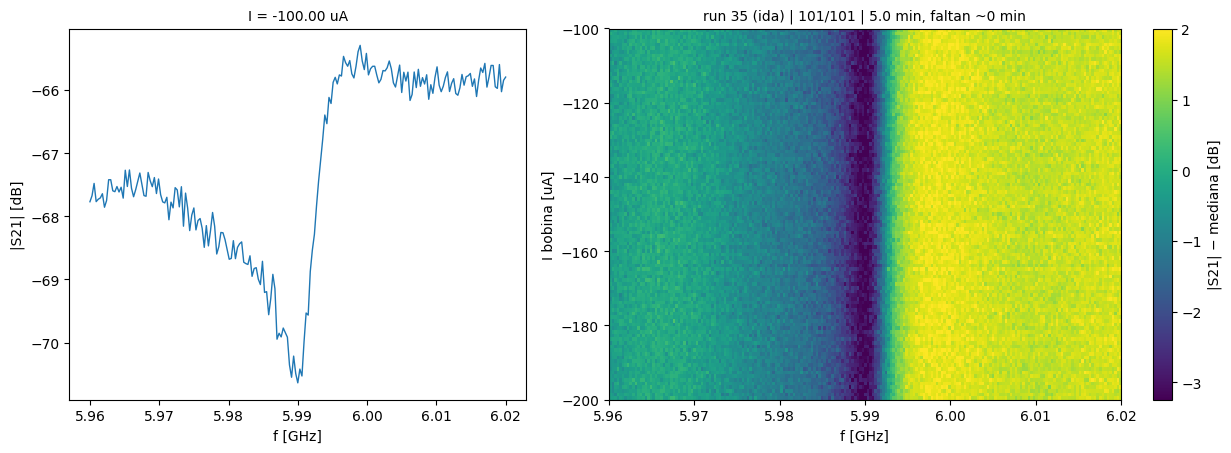

Starting experimental run with id: 35. 
run 35 (ida) listo
runs del barrido en corriente: [35]


In [105]:
I_start = -200e-6       # A
I_stop  = -100e-6       # A (incluido)
I_step  =  1e-6         # A
corrientes = np.arange(I_start, I_stop + I_step / 2, I_step)

espera       = 0.5      # s, después de llegar a cada corriente
paso_rampa   = 1e-6     # A, paso de la rampa entre corrientes (None = salto directo)
ida_y_vuelta = False     # mide también de vuelta (otro run) para ver histéresis
volver_a     = None     # A, corriente al terminar (None = queda en la última)

# llegar al inicio con rampa antes de empezar
fuente.rampa(corrientes[0], paso=paso_rampa)
time.sleep(1)

bI = barrido_corriente(pna, fuente, corrientes, espera=espera, paso_rampa=paso_rampa,
                       resonador=resonador, ida_y_vuelta=ida_y_vuelta, volver_a=volver_a,
                       att_vna=att_vna, notas=notas)
runs_I = [r['run_id'] for r in bI['runs']]
print('runs del barrido en corriente:', runs_I)

In [108]:
# llegar al inicio con rampa antes de empezar
fuente.rampa(-139.4e-6, paso=0.1e-6)
time.sleep(1)

### Resultado del barrido en corriente
Ajuste notch de cada traza → fr, Qi y κ vs corriente. Las líneas rojas marcan saltos de fr.
Para ver uno viejo: `runs_I = [12, 13]` (ida, vuelta).

In [17]:
%matplotlib inline

run 35 (ida): 101 corrientes | fr 5.992304-5.992652 GHz (rango 3.48e+05 Hz) | ajustes dudosos: 0


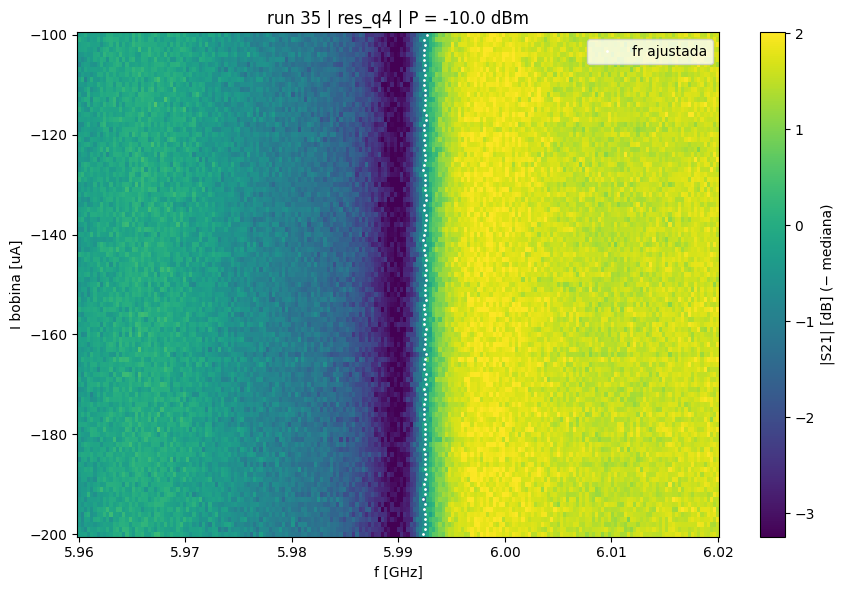

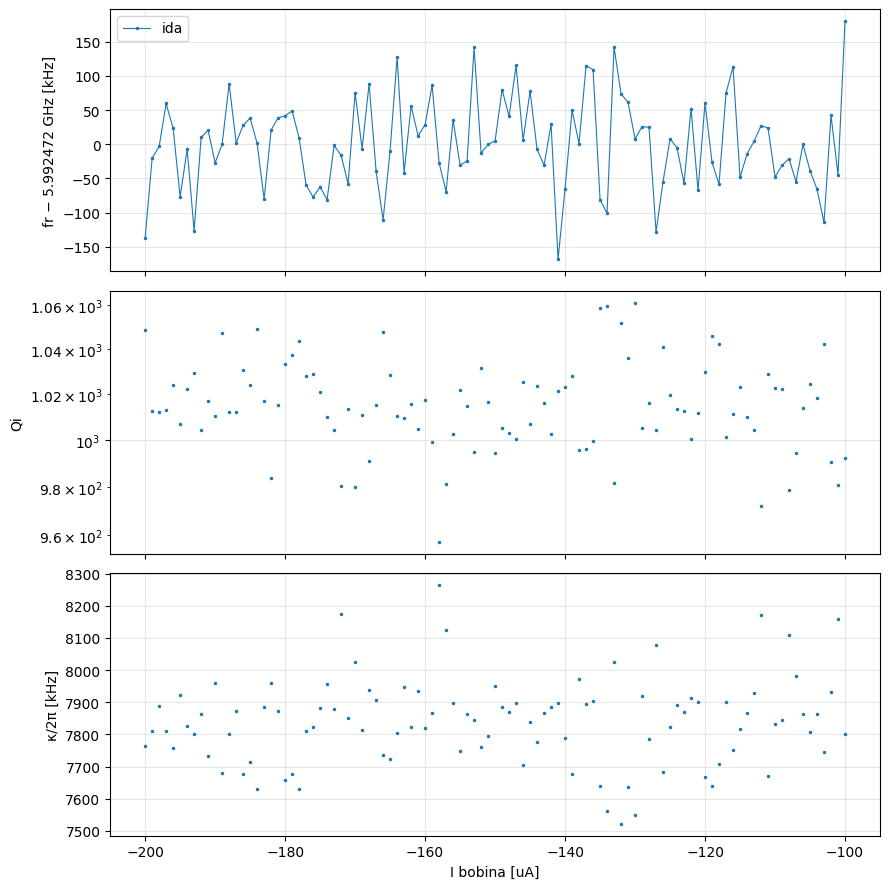

In [106]:
runs_I = [35]
normalizar = True       # resta la mediana de cada traza en el mapa

resI = []
for rid in runs_I:
    d = cargar_barrido_corriente(rid)
    a = ajustar_barrido_corriente(d)
    resI.append((d, a))
    s = saltos(a['I_uA'], a['fr'])
    a['saltos'] = s
    print(f"run {rid} ({d['metadata'].get('sentido', '')}): {len(d['I_uA'])} corrientes | "
          f"fr {np.nanmin(a['fr'])/1e9:.6f}-{np.nanmax(a['fr'])/1e9:.6f} GHz "
          f"(rango {np.nanmax(a['fr']) - np.nanmin(a['fr']):.3g} Hz) | ajustes dudosos: {np.sum(~a['ok'])}")
    for x in sorted(s, key=lambda x: x['I']):
        print(f"   salto en I = {x['I']:7.1f} uA: {x['df']/1e3:+5.0f} ± {x['df_err']/1e3:.0f} kHz (en el sentido del barrido)")
    if len(s) >= 2:
        pos = np.sort([x['I'] for x in s])
        T0 = np.median(np.diff(pos))
        n_ = np.r_[0, np.cumsum(np.round(np.diff(pos) / T0))]        # índice entero de cada salto
        if len(s) >= 3:
            pT, cT = np.polyfit(n_, pos, 1, cov=True)
            print(f"   periodo de los saltos: {pT[0]:.2f} ± {np.sqrt(cT[0, 0]):.2f} uA ({len(s)} saltos)")
        else:
            print(f"   separación de los saltos: {T0:.2f} uA")

# ---- mapa |S21|(f, I) del primer run (ida) con fr ajustada encima ----
d, a = resI[0]
o = np.argsort(d['I_uA'])
S = 20 * np.log10(np.abs(d['Z'][o]))
if normalizar:
    S = S - np.median(S, axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(9, 6))
pc = ax.pcolormesh(d['f'] / 1e9, d['I_uA'][o], S, shading='nearest', cmap='viridis',
                   vmin=np.percentile(S, 1), vmax=np.percentile(S, 99))
ax.plot(a['fr'][o] / 1e9, a['I_uA'][o], 'w.', ms=2, label='fr ajustada')
fig.colorbar(pc, ax=ax, label='|S21| [dB]' + (' (− mediana)' if normalizar else ''))
ax.set_xlabel('f [GHz]'); ax.set_ylabel('I bobina [uA]')
ax.set_title(f"run {d['run_id']} | {d['metadata'].get('resonador', '')} | P = {d['metadata'].get('pow_vna')} dBm")
ax.legend(loc='upper right')
fig.tight_layout(); plt.show()

# ---- fr, Qi, κ vs corriente (ida y vuelta) ----
fig, axs = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
for (d, a), c in zip(resI, ('C0', 'C3')):
    lab = d['metadata'].get('sentido', str(d['run_id']))
    ok = a['ok']
    axs[0].plot(a['I_uA'], (a['fr'] - np.nanmedian(resI[0][1]['fr'])) / 1e3, '.-', ms=3, lw=0.8, color=c, label=lab)
    axs[1].plot(a['I_uA'][ok], a['Qi'][ok], '.', ms=3, color=c)
    axs[2].plot(a['I_uA'][ok], a['kappa'][ok] / 1e3, '.', ms=3, color=c)
    for x in a['saltos']:
        axs[0].axvline(x['I'], color=c, ls='--', lw=0.8, alpha=0.7)
axs[0].set_ylabel(f"fr − {np.nanmedian(resI[0][1]['fr'])/1e9:.6f} GHz [kHz]"); axs[0].legend()
axs[1].set_ylabel('Qi'); axs[1].set_yscale('log')
axs[2].set_ylabel('κ/2π [kHz]'); axs[2].set_xlabel('I bobina [uA]')
for x in axs: x.grid(alpha=0.3)
fig.tight_layout(); plt.show()

C:\Users\Leandro\AppData\Local\Temp\ipykernel_10920\354768303.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.set_ylim(-ventana / 1e6, ventana / 1e6); ax.legend(loc='upper right')


Δ|S21| [dB]: rms 0.175, máx |Δ| 0.993
Δfase [°]: rms 1.17, máx |Δ| 6.6
f0 = 5.992503 GHz | fr ajustada: 5.992345–5.992653 GHz


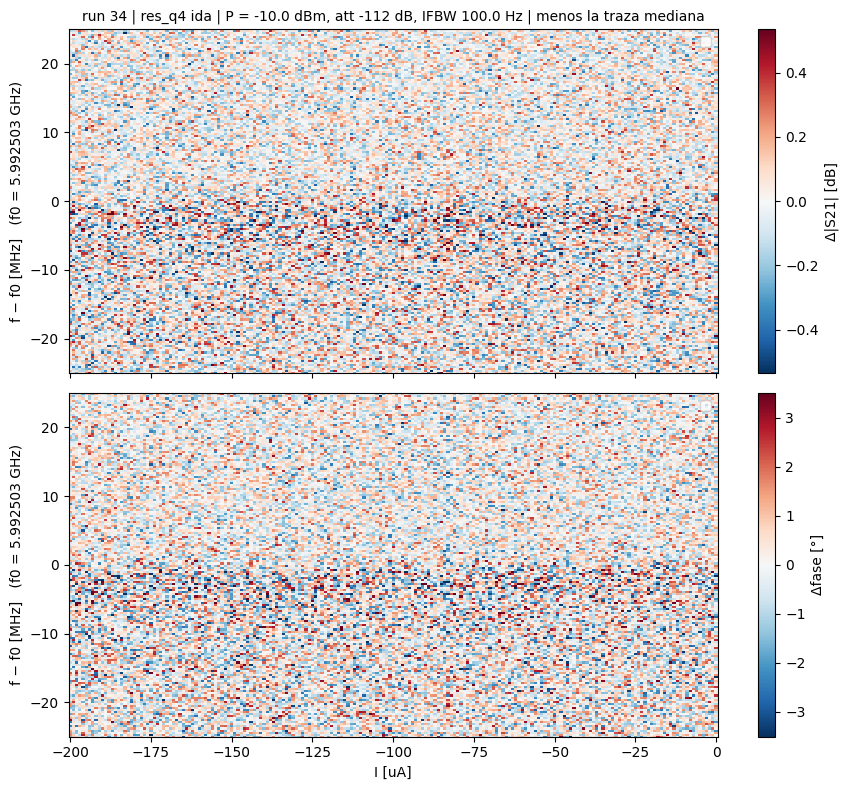

In [103]:
# ---- mapas Δ|S21| y Δfase de un run, menos la traza mediana ----
# Cada traza se normaliza con el fondo del ajuste notch (retardo eléctrico + fondo complejo lineal).
# El eje vertical es f − f0, con la MISMA f0 para todas las trazas (no la fr de cada una),
# así un corrimiento de fr se ve como tal y las líneas extra quedan en su frecuencia real.
run_mapa = 34
f0       = None      # Hz, frecuencia común que se resta; None = mediana de las fr ajustadas del run
ventana  = 25e6      # Hz, medio ancho del eje f − f0 que se muestra
pct      = 99.5      # percentil para la escala de color (simétrica)

dm = cargar_barrido_corriente(run_mapa)
Im, fm = dm['I_uA'], dm['f']
mag = np.full((len(Im), len(fm)), np.nan)
fas = np.full((len(Im), len(fm)), np.nan)
frm = np.full(len(Im), np.nan)
for i in range(len(Im)):
    try:
        r = ajustar_notch(fm, dm['Z'][i])
    except Exception:
        continue                                   # ajuste fallido: fila en NaN
    frm[i] = r['fr']
    mag[i] = np.interp(fm, r['_f'], 20 * np.log10(np.abs(r['_zn'])), left=np.nan, right=np.nan)
    fas[i] = np.interp(fm, r['_f'], np.degrees(np.unwrap(np.angle(r['_zn']))), left=np.nan, right=np.nan)

f0_usada = np.nanmedian(frm) if f0 is None else f0
o = np.argsort(Im)
dmag = (mag - np.nanmedian(mag, axis=0))[o]
dfas = (fas - np.nanmedian(fas, axis=0))[o]
y = (fm - f0_usada) / 1e6
md = dm['metadata']
fig, axs = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
for ax, M, lab in ((axs[0], dmag, 'Δ|S21| [dB]'), (axs[1], dfas, 'Δfase [°]')):
    v = np.nanpercentile(np.abs(M), pct)
    pc = ax.pcolormesh(Im[o], y, M.T, shading='nearest', cmap='RdBu_r', vmin=-v, vmax=v)
    fig.colorbar(pc, ax=ax, label=lab)
    #ax.plot(Im[o], (frm[o] - f0_usada) / 1e6, 'k.', ms=2, label='fr ajustada')
    ax.set_ylabel(f'f − f0 [MHz]   (f0 = {f0_usada / 1e9:.6f} GHz)')
    ax.set_ylim(-ventana / 1e6, ventana / 1e6); ax.legend(loc='upper right')
    print(f"{lab}: rms {np.nanstd(M):.3g}, máx |Δ| {np.nanmax(np.abs(M)):.3g}")
print(f"f0 = {f0_usada / 1e9:.6f} GHz | fr ajustada: {np.nanmin(frm) / 1e9:.6f}–{np.nanmax(frm) / 1e9:.6f} GHz")
axs[0].set_title(f"run {run_mapa} | {md.get('resonador', '')} {md.get('sentido', '')} | "
                 f"P = {md.get('pow_vna')} dBm, att {md.get('att_vna')} dB, IFBW {md.get('bw_vna')} Hz | menos la traza mediana",
                 fontsize=10)
axs[1].set_xlabel('I [uA]')
fig.tight_layout(); plt.show()

## 2) Ir a la corriente elegida y verificar
Elegí `I_acople` en el barrido de arriba, donde el resonador más se corre por el qubit.
Opcional: `I_ref`, una corriente donde no se corre, para comparar (a potencia alta las dos deberían dar la misma fr).

Por la histéresis (vórtices / flujo atrapado) conviene llegar siempre desde el mismo lado:
`desde_abajo=True` llega subiendo, como en la ida del barrido. Verificá que fr coincida con la del barrido;
si no, cambió el estado (entró un vórtice) y hay que volver a buscar la corriente.

In [ ]:
I_acople = 50e-6         # A
I_ref    = None          # A, corriente de referencia (o None)
desde_abajo = True

corrientes_punch = [I for I in (I_acople, I_ref) if I is not None]

fuente.ir_a(corrientes_punch[0], desde_abajo=desde_abajo, paso=1e-6)
time.sleep(1)
r = medir_single(pna, nombre=f'check_{resonador}', graficar=False, att_vna=att_vna,
                 resonador=resonador, notas=notas, current_uA=corrientes_punch[0] * 1e6)
z = traza_s21(r)['sdata']
chk = ajustar_notch(r['x'], z)

# fr esperada según el barrido en corriente (ida)
d, a = resI[0]
j = np.argmin(np.abs(a['I_uA'] - corrientes_punch[0] * 1e6))
print(f"I = {corrientes_punch[0]*1e6:.2f} uA | fr ahora = {chk['fr']/1e9:.6f} GHz | "
      f"fr en el barrido (I = {a['I_uA'][j]:.2f} uA) = {a['fr'][j]/1e9:.6f} GHz | "
      f"diferencia {(chk['fr'] - a['fr'][j])/1e3:+.0f} kHz (κ/2π = {chk['kappa']/1e3:.0f} kHz)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(d['f'] / 1e9, 20 * np.log10(np.abs(d['Z'][j])), lw=1, label=f"barrido, run {d['run_id']}")
ax.plot(r['x'] / 1e9, 20 * np.log10(np.abs(z)), lw=1, label=f"ahora, run {r['run_id']}")
ax.set_xlabel('f [GHz]'); ax.set_ylabel('|S21| [dB]'); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

## 3) Barrido en potencia en la corriente elegida
Un run por potencia (formato de `vna_single.barrido_potencia`), con `current_uA` en la metadata.
Conviene ir de potencia baja a alta y bajar el IFBW a potencia baja para mantener la relación señal-ruido.
El PNA llega a −30 dBm sin la opción de atenuador interno; para menos, atenuación externa.

In [ ]:
potencias = np.arange(-30, 14, 1)                 # dBm en el VNA (el PNA llega a +13)

# IFBW proporcional a la potencia: mantiene la misma relación señal-ruido en todo el barrido.
# ifbw_ref = el IFBW que da buen ruido a P_ref (medilo antes); se limita entre 1 Hz y 1 kHz.
P_ref, ifbw_ref = -30, 10
ifbw_P = lambda p: float(np.clip(ifbw_ref * 10 ** ((p - P_ref) / 10), 1, 1000))
avg_P     = None

bps = []
for I in corrientes_punch:
    fuente.ir_a(I, desde_abajo=desde_abajo, paso=1e-6)
    time.sleep(1)
    print(f'--- I = {I*1e6:.2f} uA ---')
    b = barrido_potencia(pna, potencias, ifbw=ifbw_P, averages=avg_P, resonador=resonador,
                         graficar=False, att_vna=att_vna, notas=notas, current_uA=I * 1e6)
    bps.append(dict(current_uA=I * 1e6, **b))
print('tags:', [b['barrido'] for b in bps])

### Resultado del barrido en potencia
- Mapa |S21|(f, P) para cada corriente.
- fr, Qi y profundidad del dip vs potencia. **Punch-out**: fr salta (o se corre rápido) a una potencia y
  queda fija por encima; si mediste también `I_ref`, a potencia alta las dos corrientes convergen a la misma fr.
- `att_entrada`: atenuación de la línea de entrada hasta el chip [dB, negativa] para poner el eje de fotones
  (None = no calcular). Solo la entrada: no sumar la ganancia del amplificador de salida.

Para ver uno viejo: `bps = [dict(current_uA=50, **buscar_barrido('20261107_160000'))]`.

In [ ]:
# bps = [dict(current_uA=50, **buscar_barrido('20261107_160000'))]
att_entrada = att_vna     # dB, atenuación total de entrada (None = no calcular fotones)
normalizar  = True

resP = [(b, ajustar_runs(b['runs'])) for b in bps]

# ---- mapas |S21|(f, P) ----
fig, axs = plt.subplots(1, len(resP), figsize=(6.5 * len(resP), 5), squeeze=False)
for ax, (b, a) in zip(axs[0], resP):
    o = np.argsort(a['P'])
    S = 20 * np.log10(np.abs(a['Z'][o]))
    if normalizar:
        S = S - np.median(S, axis=1, keepdims=True)
    pc = ax.pcolormesh(a['f'] / 1e9, a['P'][o], S, shading='nearest', cmap='viridis',
                       vmin=np.percentile(S, 1), vmax=np.percentile(S, 99))
    ax.plot(a['fr'][o] / 1e9, a['P'][o], 'w.', ms=3)
    fig.colorbar(pc, ax=ax, label='|S21| [dB]' + (' (− mediana)' if normalizar else ''))
    ax.set_xlabel('f [GHz]'); ax.set_ylabel('P VNA [dBm]')
    ax.set_title(f"I = {b['current_uA']:.2f} uA | {b['barrido']}", fontsize=10)
fig.tight_layout(); plt.show()

# ---- fr, Qi, profundidad vs potencia ----
fig, axs = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
for (b, a), c in zip(resP, ('C0', 'C3', 'C2', 'C1')):
    o = np.argsort(a['P']); P = a['P'][o]; ok = a['ok'][o]
    lab = f"I = {b['current_uA']:.2f} uA"
    axs[0].errorbar(P, a['fr'][o] / 1e9, yerr=a['fr_err'][o] / 1e9, fmt='.-', ms=4, lw=0.8, color=c, label=lab)
    axs[1].errorbar(P[ok], a['Qi'][o][ok], yerr=a['Qi_err'][o][ok], fmt='.', ms=4, color=c)
    axs[2].plot(P, a['caida_db'][o], '.-', ms=4, lw=0.8, color=c)
    if att_entrada is not None:
        n = numero_fotones(P, att_entrada, a['fr'][o], a['Ql'][o], a['Qc'][o])
        print(f"{lab}: <n> de {np.nanmin(n):.3g} a {np.nanmax(n):.3g} fotones")
axs[0].set_ylabel('fr [GHz]'); axs[0].legend()
axs[1].set_ylabel('Qi'); axs[1].set_yscale('log')
axs[2].set_ylabel('profundidad del dip [dB]'); axs[2].set_xlabel('P VNA [dBm]')
if att_entrada is not None:
    sec = axs[0].secondary_xaxis('top', functions=(lambda p: p + att_entrada, lambda q: q - att_entrada))
    sec.set_xlabel('P en el chip [dBm]')
for x in axs: x.grid(alpha=0.3)
fig.tight_layout(); plt.show()

### Cerrar

In [109]:
# fuente.rampa(0.0, paso=1e-6)      # descomentá para bajar la corriente a 0
pna.close()
fuente.inst.close()